In [12]:
import onnxruntime
from glob import glob
import os
from osgeo import gdal
os.getcwd()

'/home/skye/src/secondgen/data/smallContin'

In [24]:
tile_loc = "./tiles/18/*/*.tif"
available_tiles = [fname for fname in glob(tile_loc) if os.path.getsize(fname) > 4000]
available_tiles[:10], len(available_tiles)

(['./tiles/18/137057/92715.tif',
  './tiles/18/137057/92716.tif',
  './tiles/18/137058/92663.tif',
  './tiles/18/137058/92678.tif',
  './tiles/18/137058/92698.tif',
  './tiles/18/137058/92708.tif',
  './tiles/18/137058/92693.tif',
  './tiles/18/137058/92688.tif',
  './tiles/18/137058/92683.tif',
  './tiles/18/137058/92713.tif'],
 5004)

In [25]:
sample_dat: gdal.Dataset = gdal.Open(available_tiles[8])
sample_dat.RasterXSize

256

np.float32(3061.1968)

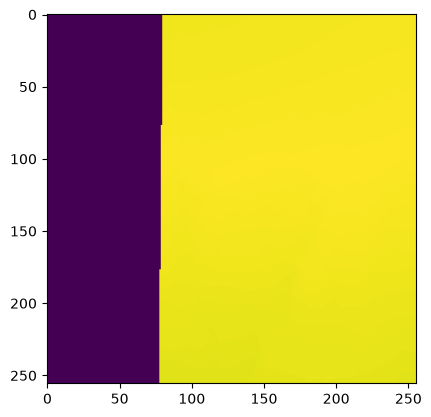

In [26]:
import matplotlib.pyplot as plt
import numpy as np
img = sample_dat.ReadAsArray()
plt.imshow(img)
np.max(img)

In [27]:
encoder_model = onnxruntime.InferenceSession("../../models/height25_encoder_latest.onnx", providers=['TensorrtExecutionProvider','CUDAExecutionProvider'])
decoder_model = onnxruntime.InferenceSession("../../models/height25_decoder_latest.onnx", providers=['TensorrtExecutionProvider','CUDAExecutionProvider'])

In [43]:
def get_normalized(data):
    max_val = np.amax(data)
    min_val = np.amin(data)
    extent = max(max_val - min_val, 0.01)
    return {
        "normalized": (data - min_val) / extent,
        "scaleFactor": extent,
        "min": min_val
    }

norm_sample = get_normalized(sample_dat.ReadAsArray())
sample_dat.ReadAsArray().shape

(256, 256)

In [29]:

gdal_tiles = [gdal.Open(fname) for fname in available_tiles]
tile_data = [t.ReadAsArray() for t in gdal_tiles]
normalized_rasters = [get_normalized(tile_datum) for tile_datum in tile_data]

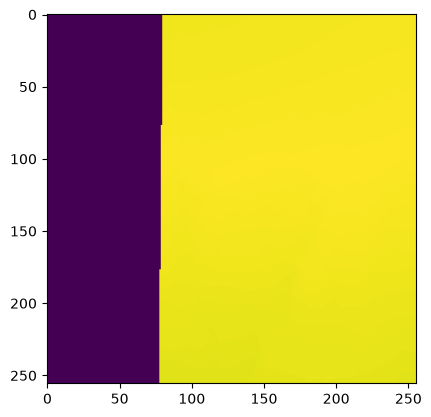

In [38]:
test1 = encoder_model.run(["latent"], {"image": np.array([[norm_sample["normalized"]]])})
test1_dec = decoder_model.run(["image"], {"latent": test1[0]})
plt.imshow(norm_sample["normalized"])


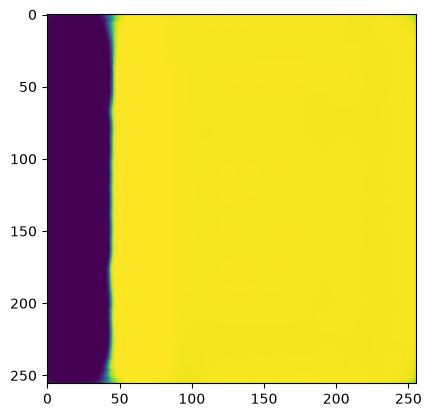

In [44]:
def process_raster(data_dict):
    latent = encoder_model.run(["latent"], {"image": np.array([[data_dict["normalized"]]])})
    output = decoder_model.run(["image"], {"latent": latent[0]})[0]
    output *= data_dict["scaleFactor"]
    output += data_dict["min"]
    return output[0][0]
processed_rasters = [process_raster(norm_data) for norm_data in normalized_rasters]
plt.imshow(processed_rasters[42])

In [45]:
unique_names = set([tilename.split("/")[-1] for tilename in available_tiles])
len(unique_names), len(available_tiles)

(59, 5004)

In [47]:
driver_tiff = gdal.GetDriverByName("GTiff")
for tile_i in range(len(gdal_tiles)):
    path_parts = available_tiles[tile_i].split("/")
    copy = driver_tiff.CreateCopy(f"./tiles/output/{path_parts[-2]}_{path_parts[-1]}", gdal_tiles[tile_i])
    copy.WriteArray(processed_rasters[tile_i])
    copy.SyncToDisk()